# Next-day stockout risk on FreshRetailNet-50K

**Problem.** A replenishment team can review a limited number of store-products each evening.
Which series will run out of stock tomorrow, ranked so the top of the list is worth their time?
A second question: which aggregation level (daily, weekly, category) carries the signal?

**Prediction.** For each store-product-day D, using only what is known at the end of D, predict
whether D+1 has **more than 2 out-of-stock hours inside the 06:00 to 22:00 operating window**.

Sections: 1 data checks, 2 EDA, 3 aggregation levels, 4 additional features, 5 models and
baselines, 6 backtest, 7 test results with CIs, 8 calibration, 9 slices, 10 importance and SHAP,
11 results and suggested operating setup. Figures are written to `reports/figures/`, tables to
`reports/tables/`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

from src import checks, eda, modeling
from src.data import WAREHOUSE
from src.plots import CONFIG_COLORS, NEUTRAL, SERIES, SEQ_CMAP, TEXT_2, save, style
from src.run_sql import build_warehouse

style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
TABLES = ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

# Build the warehouse (raw parquet -> SQL models) when it is missing.
if not WAREHOUSE.exists():
    build_warehouse().close()
con = duckdb.connect(str(WAREHOUSE), read_only=True)
con.execute("SELECT COUNT(*) FROM model_dataset").fetchone()

(4150000,)

## 1. Data checks

Row counts, coverage, date ranges, missing values, duplicate keys, array lengths and
series contiguity. Then the two checks the target depends on: which value of
`hours_stock_status` means out of stock, and which hour indices form the 06:00 to 22:00 window
counted by `stock_hour6_22_cnt`.

In [2]:
dc = checks.run_all(con)
dc["files"]

,table,rows,stores,products,store_products,cities,first_categories,min_dt,max_dt,days,eval_follows_train,gap_days
0,raw_train,4500000,898,865,50000,18,32,2024-03-28,2024-06-25,90,None,NaN
1,raw_eval,350000,898,865,50000,18,32,2024-06-26,2024-07-02,7,True,1.0


In [3]:
display(dc["series_overlap"])
display(dc["duplicates"])
display(dc["arrays"])
display(dc["contiguity"])
missing = dc["missing"]
print("Columns with any missing value:",
      missing[(missing.raw_train > 0) | (missing.raw_eval > 0)].column.tolist() or "none")

,eval_series,eval_series_in_train
0,50000,50000


,table,duplicate_keys
0,raw_train,0
1,raw_eval,0
2,train + eval combined,0


,table,hours_sale_len_not_24,hours_stock_status_len_not_24,stock_status_min,stock_status_max
0,raw_train,0,0,0,1
1,raw_eval,0,0,0,1


,series,contiguous_series,min_days,max_days
0,50000,50000.0,97,97


Columns with any missing value: none


### Stock status coding and the operating window

For several candidate hour ranges we count the 1s (and separately the 0s) of `hours_stock_status`
and check how often that count equals `stock_hour6_22_cnt`.

In [4]:
dc["window_match"]

,"hours (0-based, inclusive)",n_hours,share_rows_count_of_1_matches,share_rows_count_of_0_matches
0,6..21,16,1.000000,0.024848
1,6..22,17,0.580815,0.023147
2,5..21,17,0.825986,0.005846
3,7..22,16,0.619909,0.001388
4,5..22,18,0.518012,0.005050
5,6..20,15,0.590106,0.023239


In [5]:
display(dc["status_vs_sales"])
display(dc["full_day_status"])

,stock_status,hours,mean_hourly_sale,share_hours_with_sale
0,0,62274433,0.073837,0.380958
1,1,15325567,0.004968,0.029268


,day_type,days,mean_daily_sales,share_days_with_sale
0,all 16 window hours = 0,2714556,0.994501,0.981310
1,all 16 window hours = 1,194332,0.045251,0.184926


In [6]:
wm = dc["window_match"].set_index("hours (0-based, inclusive)")
svs = dc["status_vs_sales"].set_index("stock_status")
print(f"Count of 1s over hours 6..21 matches stock_hour6_22_cnt on "
      f"{wm.loc['6..21', 'share_rows_count_of_1_matches']:.2%} of train rows; "
      f"best alternative: {wm.drop('6..21').share_rows_count_of_1_matches.max():.2%}.")
print(f"Hours coded 1 record a sale {svs.loc[1, 'share_hours_with_sale']:.1%} of the time, "
      f"hours coded 0 {svs.loc[0, 'share_hours_with_sale']:.1%}.")

Count of 1s over hours 6..21 matches stock_hour6_22_cnt on 100.00% of train rows; best alternative: 82.60%.
Hours coded 1 record a sale 2.9% of the time, hours coded 0 38.1%.


**Verdict.**

- **1 = out of stock, 0 = in stock.** Hours coded 1 almost never record a sale, days coded 1 for
  all 16 window hours average about 0.05 units sold versus about 1 unit for days coded 0 for all
  16 hours, and a count of 1s (not 0s) reproduces `stock_hour6_22_cnt`. So
  `stock_hour6_22_cnt` is a count of **out-of-stock** hours despite its name.
- **The window is array positions 6 to 21 (0-based), i.e. the 16 hours from 06:00 to 22:00.**
  This range matches on 100% of rows; no other candidate exceeds 83%.
- Eval (2024-06-26 to 2024-07-02) starts the day after train ends (2024-06-25), with the same
  50,000 store-products, so eval is used as the final test set.
- No missing values, no duplicate keys, all arrays have 24 elements, and every series is 97
  contiguous days, so row-based rolling windows equal day-based windows.

### Target prevalence and threshold

Share of labeled rows whose next day exceeds each threshold of out-of-stock window hours.

In [7]:
dc["target_prevalence"]

,split,rows,gt0,gt2_target,gt4,gt8,overnight_gt0
0,train,3100000,0.427022,0.366292,0.291693,0.143015,0.572119
1,valid,700000,0.435151,0.373949,0.296151,0.137497,0.573311
2,test,350000,0.409823,0.349769,0.277586,0.136863,0.548654


The target uses **more than 2 hours**. Moving from "any out-of-stock hour" (> 0) to > 2 drops about
one positive in seven: those are 1 to 2 hour gaps, often a shelf refill or a recording artifact,
which a replenishment team cannot act on. Three or more hours is at least 19% of the 16-hour
selling day, a material loss of selling time. Higher thresholds (> 4, > 8) shrink the positive
class without changing the nature of the problem. Prevalence at > 2 is about 35 to 37% and is
stable across train, validation and test. Overnight out-of-stock hours (positions 0 to 5 and
22 to 23) are common (about 57% of days) but mostly reflect closed hours. They are reported
separately below and are not part of the target.

## 2. Exploratory analysis

All relationships below are associations measured on observational data, not causal effects.
Sample sizes (n) are shown with every comparison.

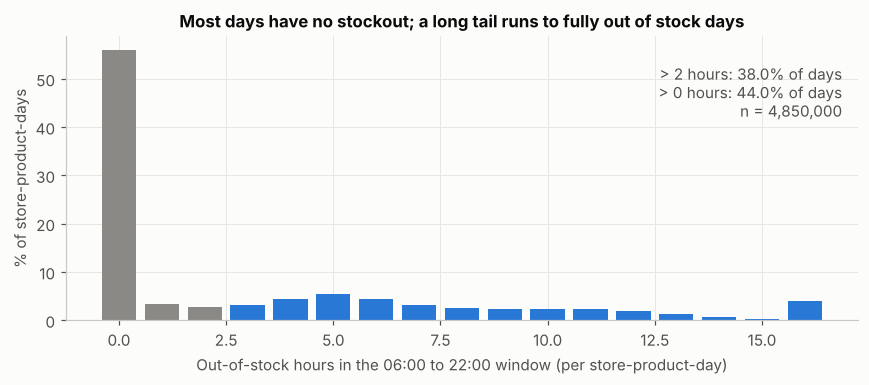

In [8]:
dist = eda.oos_hours_distribution(con)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(dist.oos_hours, dist.share * 100, color=[SERIES[0] if h > 2 else NEUTRAL for h in dist.oos_hours],
       width=0.8)
ax.set_xlabel("Out-of-stock hours in the 06:00 to 22:00 window (per store-product-day)")
ax.set_ylabel("% of store-product-days")
ax.set_title("Most days have no stockout; a long tail runs to fully out of stock days")
ax.text(0.98, 0.9, f"> 2 hours: {dist[dist.oos_hours > 2].share.sum():.1%} of days\n"
        f"> 0 hours: {dist[dist.oos_hours > 0].share.sum():.1%} of days\nn = {dist.n.sum():,}",
        transform=ax.transAxes, ha="right", va="top", color=TEXT_2)
save(fig, "eda_01_oos_hours_distribution")
plt.show()
dist.to_csv(TABLES / "eda_oos_hours_distribution.csv", index=False)

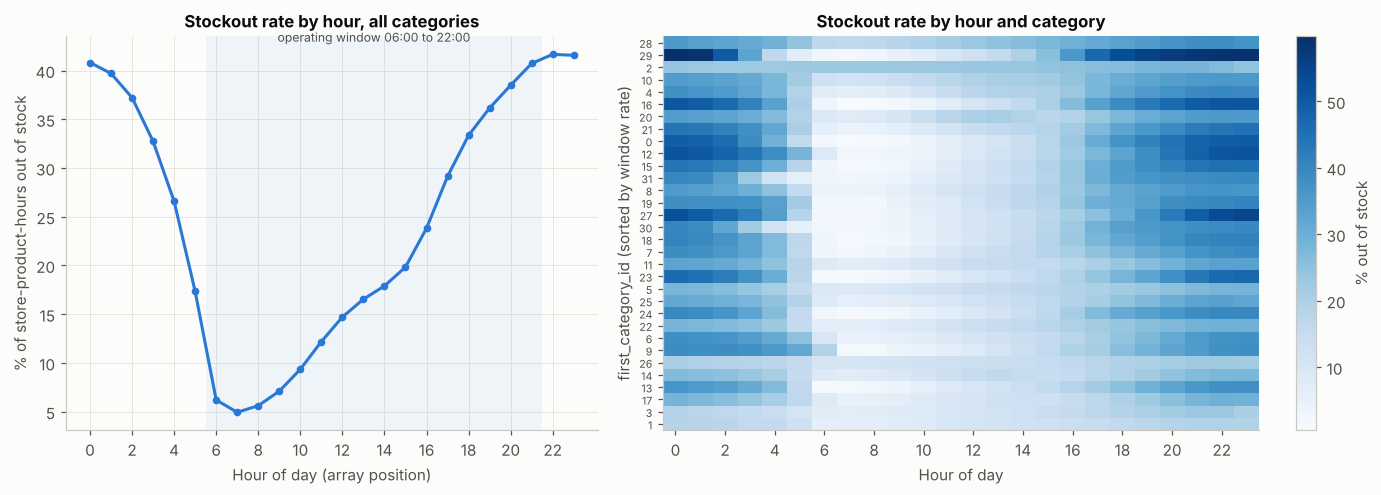

Window hours (6..21) mean rate 19.7%; overnight mean rate 34.7%


In [9]:
by_hour = eda.stockout_by_hour(con)
by_hour_cat = eda.stockout_by_hour_category(con)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.axvspan(5.5, 21.5, color=SERIES[0], alpha=0.06, lw=0)
ax.plot(by_hour.hour, by_hour.oos_rate * 100, color=SERIES[0], marker="o", ms=4)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day (array position)")
ax.set_ylabel("% of store-product-hours out of stock")
ax.set_title("Stockout rate by hour, all categories")
ax.text(13.5, by_hour.oos_rate.max() * 100 + 1, "operating window 06:00 to 22:00", ha="center",
        color=TEXT_2, va="bottom", fontsize=8)
piv = by_hour_cat.pivot(index="first_category_id", columns="hour", values="oos_rate")
piv = piv.loc[piv.loc[:, 6:21].mean(axis=1).sort_values(ascending=False).index]
ax = axes[1]
im = ax.imshow(piv.values * 100, aspect="auto", cmap=SEQ_CMAP)
ax.set_yticks(range(len(piv)), piv.index, fontsize=7)
ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
ax.grid(False)
ax.set_xlabel("Hour of day")
ax.set_ylabel("first_category_id (sorted by window rate)")
ax.set_title("Stockout rate by hour and category")
fig.colorbar(im, ax=ax, label="% out of stock")
save(fig, "eda_02_stockout_by_hour")
plt.show()
by_hour.to_csv(TABLES / "eda_stockout_by_hour.csv", index=False)
piv.to_csv(TABLES / "eda_stockout_by_hour_category.csv")
print(f"Window hours (6..21) mean rate {by_hour[by_hour.hour.between(6, 21)].oos_rate.mean():.1%}; "
      f"overnight mean rate {by_hour[~by_hour.hour.between(6, 21)].oos_rate.mean():.1%}")

The hourly profile is U-shaped: out-of-stock rates are high overnight, fall in the morning after
restocking, and climb through the afternoon and evening as shelves sell down. The overnight rate
mostly reflects closed or unstocked hours, which is why the target only counts the operating
window. Categories differ by a factor of several in their window stockout rate, so category
context is plausibly useful.

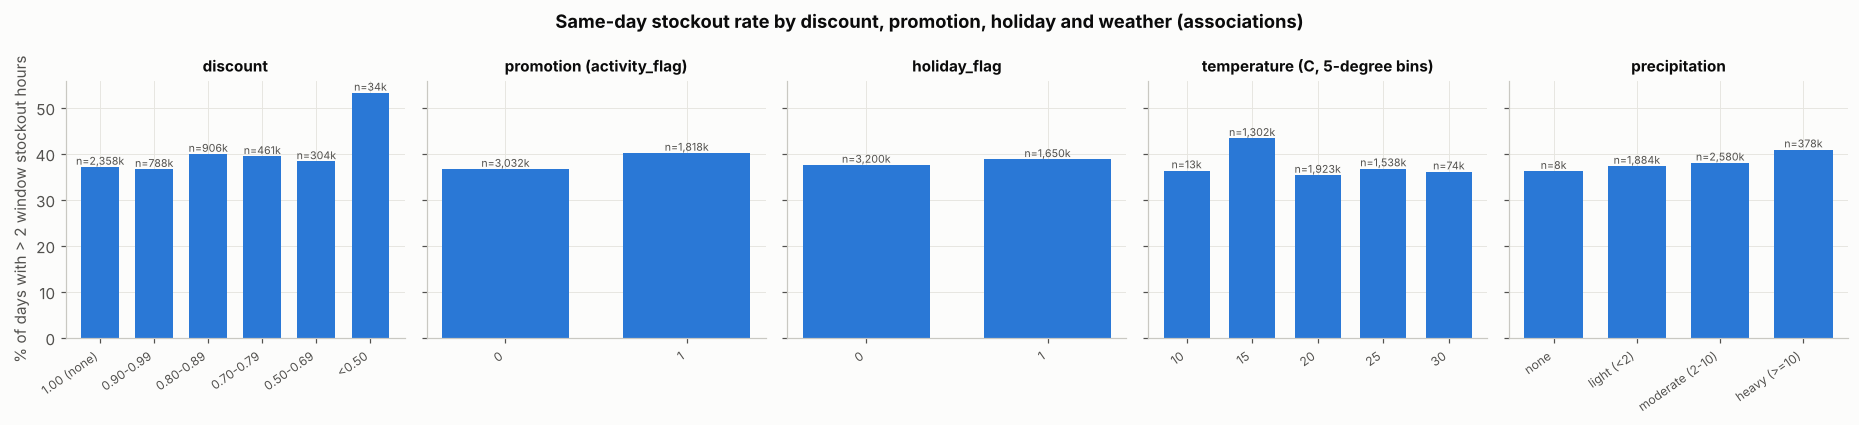

discount


,bin,n,stockout_day_rate,mean_oos_hours
0,a 1.00 (none),2357951,0.371,3.218
1,b 0.90-0.99,787668,0.366,2.732
2,c 0.80-0.89,905685,0.399,3.234
3,d 0.70-0.79,461017,0.394,3.274
4,e 0.50-0.69,303888,0.383,3.282
5,f <0.50,33791,0.532,4.429


promotion (activity_flag)


,bin,n,stockout_day_rate,mean_oos_hours
0,0,3031715,0.367,3.081
1,1,1818285,0.402,3.291


holiday_flag


,bin,n,stockout_day_rate,mean_oos_hours
0,0,3200000,0.376,3.091
1,1,1650000,0.388,3.294


temperature (C, 5-degree bins)


,bin,n,stockout_day_rate,mean_oos_hours
0,10,13107,0.363,3.350
1,15,1302281,0.434,3.705
2,20,1922949,0.354,2.912
3,25,1537742,0.368,3.015
4,30,73921,0.361,3.010


precipitation


,bin,n,stockout_day_rate,mean_oos_hours
0,0 none,8353,0.362,3.479
1,1 light (<2),1883721,0.373,3.123
2,2 moderate (2-10),2579808,0.380,3.164
3,3 heavy (>=10),378118,0.409,3.309


In [10]:
rel = {
    "discount": eda.rate_by(con, eda.DISCOUNT_BIN, "bin"),
    "promotion (activity_flag)": eda.rate_by(con, "activity_flag", "bin"),
    "holiday_flag": eda.rate_by(con, "holiday_flag", "bin"),
    "temperature (C, 5-degree bins)": eda.rate_by(con, eda.TEMP_BIN, "bin"),
    "precipitation": eda.rate_by(con, eda.PRECIP_BIN, "bin"),
}
fig, axes = plt.subplots(1, 5, figsize=(17, 3.9), sharey=True)
for ax, (name, d) in zip(axes, rel.items()):
    labels = d["bin"].astype(str).str.replace(r"^[a-z0-9] ", "", regex=True)
    ax.bar(range(len(d)), d.stockout_day_rate * 100, color=SERIES[0], width=0.7)
    ax.set_xticks(range(len(d)), labels, rotation=35, ha="right", fontsize=8)
    for i, (r, n) in enumerate(zip(d.stockout_day_rate, d.n)):
        ax.text(i, r * 100 + 0.5, f"n={n/1e3:,.0f}k", ha="center", fontsize=7, color=TEXT_2)
    ax.set_title(name, fontsize=10)
axes[0].set_ylabel("% of days with > 2 window stockout hours")
fig.suptitle("Same-day stockout rate by discount, promotion, holiday and weather (associations)",
             fontweight="bold")
save(fig, "eda_03_relationships")
plt.show()
pd.concat({k: v for k, v in rel.items()}, names=["factor"]).reset_index(level=0).to_csv(
    TABLES / "eda_relationships.csv", index=False)
for k, v in rel.items():
    print(k); display(v.round(3))

Reading these as associations:

- **Discount.** The deepest discounts (< 0.5 of list price, small n) coincide with the highest
  same-day stockout rate. This may reflect markdowns on products that are already scarce or near
  expiry, rather than discounts causing stockouts.
- **Promotion days** (`activity_flag = 1`) have a stockout-day rate about 3.5 points higher than
  other days (40.2% against 36.7%), and **holidays** about 1 point higher (38.8% against 37.6%).
- **Weather.** Heavy rain is associated with slightly more stockouts. Cooler days (15 to 20 C)
  show the highest rate, but temperature is confounded with season and with the calendar.

All of these differences are small next to the persistence effect shown below.

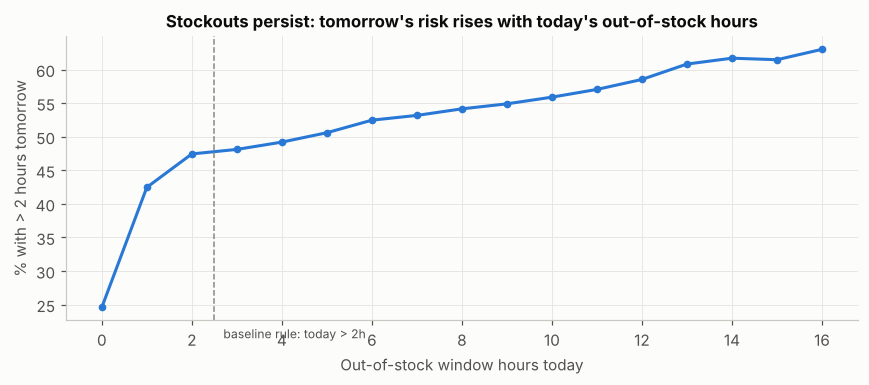

,today,n,p_tomorrow_stockout
0,today <= 2h,2629368,0.265
1,today > 2h,1520632,0.541


In [11]:
pers = eda.persistence(con)
pers_h = eda.persistence_by_hours(con)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(pers_h.oos_hours, pers_h.p_tomorrow_stockout * 100, color=SERIES[0], marker="o", ms=4)
ax.axvline(2.5, color=NEUTRAL, ls="--", lw=1)
ax.set_xlabel("Out-of-stock window hours today")
ax.set_ylabel("% with > 2 hours tomorrow")
ax.set_title("Stockouts persist: tomorrow's risk rises with today's out-of-stock hours")
ax.text(2.7, 20, "baseline rule: today > 2h", color=TEXT_2, fontsize=8)
save(fig, "eda_04_persistence")
plt.show()
pers.to_csv(TABLES / "eda_persistence.csv", index=False)
display(pers.round(3))

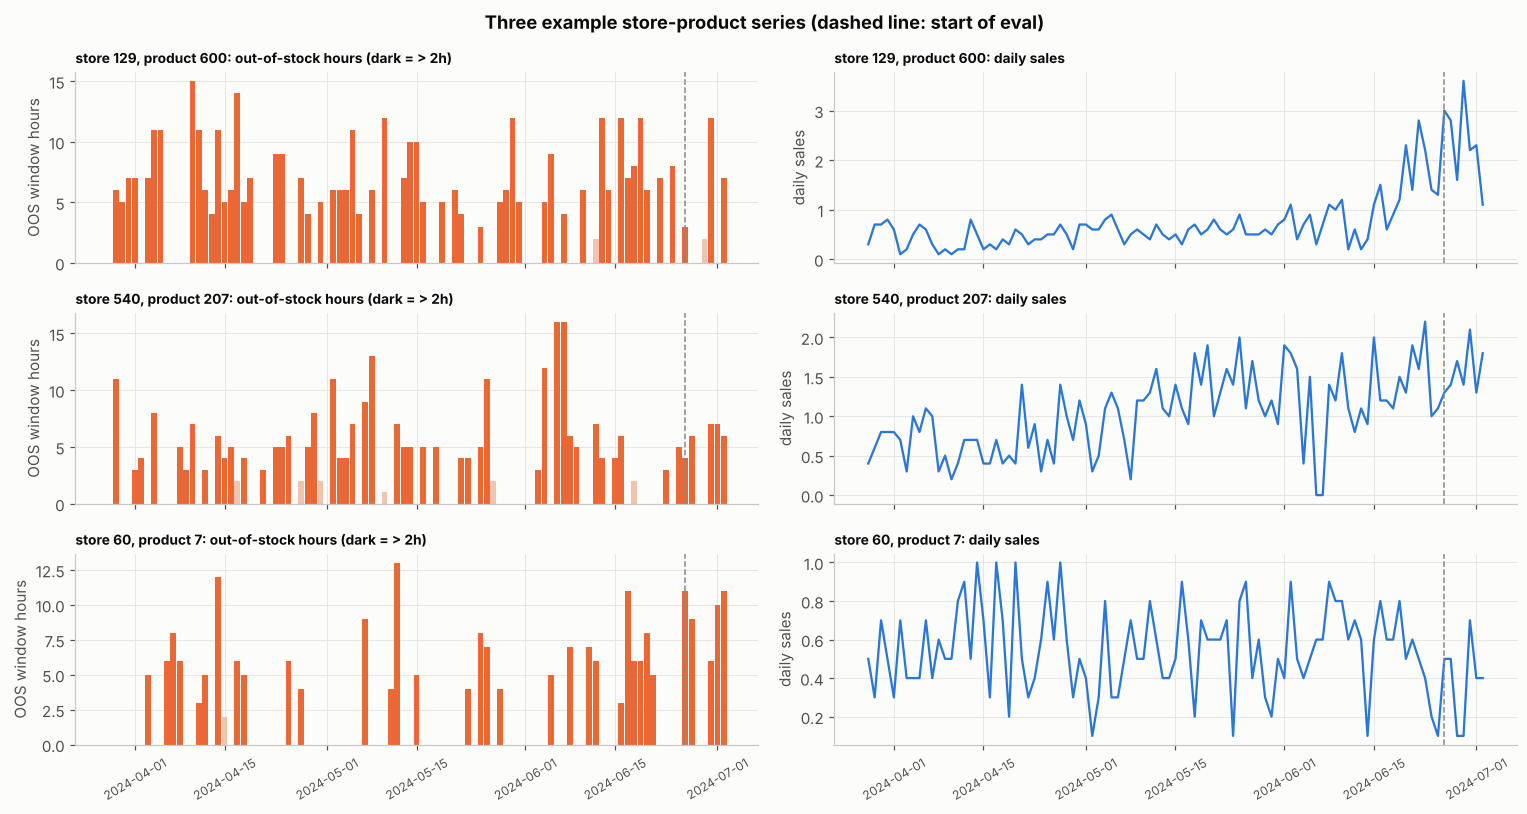

In [12]:
ex = eda.example_series(con)
keys = ex[["store_id", "product_id"]].drop_duplicates().values.tolist()
fig, axes = plt.subplots(len(keys), 2, figsize=(14, 2.5 * len(keys)), sharex=True)
for (ax_o, ax_s), (s, p) in zip(axes, keys):
    d = ex[(ex.store_id == s) & (ex.product_id == p)]
    ax_o.bar(d.dt, d.oos_hours, color=[SERIES[1] if h > 2 else "#f2c3ad" for h in d.oos_hours], width=0.9)
    ax_o.set_ylabel("OOS window hours")
    ax_o.set_title(f"store {s}, product {p}: out-of-stock hours (dark = > 2h)", loc="left", fontsize=9)
    ax_s.plot(d.dt, d.sale_amount, color=SERIES[0], lw=1.5)
    ax_s.set_ylabel("daily sales")
    ax_s.set_title(f"store {s}, product {p}: daily sales", loc="left", fontsize=9)
    for ax in (ax_o, ax_s):
        ax.axvline(pd.Timestamp("2024-06-26"), color=NEUTRAL, ls="--", lw=1)
        ax.tick_params(axis="x", labelrotation=30, labelsize=8)
fig.suptitle("Three example store-product series (dashed line: start of eval)", fontweight="bold")
save(fig, "eda_05_example_series")
plt.show()

Stockout days cluster in runs, and the frequency of stockouts changes over time within a series
(for example a busier late June). Sales usually continue on stockout days, because the shelf
often empties part way through the day, but sales during out-of-stock hours are lost. Daily sales
are therefore censored demand, which is why the daily features include in-stock sales and sales
per available hour as well as raw sales.

## 3. Aggregation levels

Every feature set is joined onto the same daily prediction rows (store, product, D), produced by
the SQL layer in `sql/` (`stg_` -> `int_` -> `features_` -> `model_dataset`). Each non-daily
config also carries the same three calendar fields (day of week, holiday today, holiday
tomorrow), so the configs differ only in the aggregation level of the stock and sales signals.

**Leakage rule.** Every feature is known at the end of D. Nothing realized on D+1 is a feature,
except the D+1 holiday flag (a calendar fact). `tests/test_leakage.py` enforces this by
scrambling all data after a cutoff, rebuilding the warehouse, and checking that features up to
the cutoff do not change.

In [13]:
split_summary = con.execute('''
    SELECT split, COUNT(*) AS rows, MIN(dt) AS first_D, MAX(dt) AS last_D,
           MIN(label_dt) AS first_label_day, MAX(label_dt) AS last_label_day, AVG(label) AS prevalence
    FROM model_dataset GROUP BY 1 ORDER BY first_D
''').df()
split_summary.to_csv(TABLES / "split_summary.csv", index=False)
split_summary

,split,rows,first_D,last_D,first_label_day,last_label_day,prevalence
0,train,3100000,2024-04-10,2024-06-10,2024-04-11,2024-06-11,0.366292
1,valid,700000,2024-06-11,2024-06-24,2024-06-12,2024-06-25,0.373949
2,test,350000,2024-06-25,2024-07-01,2024-06-26,2024-07-02,0.349769


**Temporal split** (by the label day D+1). Eval follows train, so the eval days are the test set.
Validation is the last 14 days of train, and training is everything before that. The first 13
days of each series are dropped as warm-up, so every row has 14 days of history. Features for
the first test rows use train-period history; that is allowed, because features only look
backward from D.

## 4. Additional features: intraday, history, entity, demand

Four more groups are built in SQL (`sql/09` to `sql/12`) and joined in `features_all`. All of them
are known at the end of D; the leakage test scrambles every raw value after a cutoff and checks
that none of them changes.

- **intraday:** out of stock at close (hour 21), OOS hours 19 to 21, OOS hours at 22 and 23 (outside
  the target window but known at the end of D), first OOS hour, last in-stock hour, an OOS hour after
  the first sale (sell-out), OOS at hour 23, lag 1 and 7-day mean of OOS at close;
- **history:** expanding per-series mean OOS hours and share of days with more than 2 OOS hours
  (no days-observed count: every series starts on the same day, so it would act as a date index);
- **entity:** stockout rate of the same product in the other stores and of the store's other
  products in the same second category (both leave-one-out, so the row's own value is excluded),
  and of the store across all its products, for D and the trailing 7 days, plus the second and
  third category ids (LightGBM categoricals; logistic regression uses the rates only);
- **demand:** censored-demand estimate (in-stock sales rate x 16), estimated lost sales and their
  7-day means.

The config `full` is `combined` plus all four groups.

In [14]:
groups = {"daily": modeling.DAILY, "weekly": modeling.WEEKLY, "category": modeling.CATEGORY,
          "calendar": modeling.CALENDAR, **modeling.NEW_GROUPS}
cfg_table = pd.DataFrame([
    {"config": k, "n_features": len(v), "features": ", ".join(v)} for k, v in modeling.CONFIGS.items()
])
cfg_table.to_csv(TABLES / "feature_configs.csv", index=False)
display(pd.DataFrame([{"group": g, "n": len(f), "features": ", ".join(f)} for g, f in groups.items()]))
new_cols = sum(modeling.NEW_GROUPS.values(), [])
con.execute(f"SELECT {', '.join(f'AVG(CAST({c} AS DOUBLE)) AS {c}' for c in new_cols)} "
            "FROM model_dataset").df().T.rename(columns={0: "mean"}).round(3)

,group,n,features
0,daily,30,"oos_hours, oos_fraction, longest_oos_run, in_s..."
1,weekly,11,"wk_oos_hours_sum, wk_oos_days, wk_any_oos_days..."
2,category,10,"first_category_id, cat_n_products, cat_oos_rat..."
3,calendar,3,"day_of_week, holiday_flag, holiday_tomorrow"
4,intraday,9,"oos_at_close, oos_hours_last3, oos_hours_late_..."
5,history,2,"hist_oos_hours_mean, hist_oos_day_share"
6,entity,8,"second_category_id, third_category_id, prod_oo..."
7,demand,4,"demand_est, lost_sales_est, demand_est_mean_7d..."


,mean
oos_at_close,0.394
oos_hours_last3,1.113
oos_hours_late_night,0.806
first_oos_hour,13.947
last_in_stock_hour,18.677
oos_after_sale,0.381
ended_day_oos,0.403
oos_at_close_lag1,0.396
oos_at_close_mean_7d,0.402
hist_oos_hours_mean,3.463


## 5. Models and baselines

The pipeline (`make backtest train report`) writes every table used below; this notebook reads them
and refits nothing, except when they are missing.

- **Baselines, scored as rankings:** today's OOS hours (the rule "today > 2h"), 7-day mean
  OOS hours, expanding per-series stockout share, and a logistic regression on OOS hours plus OOS at
  close.
- **Logistic regression** and **LightGBM** on daily, weekly, category, combined and full. Both model
  types train on the same rows: the full train split.
- **Ablation:** LightGBM on `full` minus one added group at a time.
- Thresholds (F1-optimal) and calibration are fitted on validation; the test week is scored once.

In [15]:
import subprocess
needed = [modeling.BACKTEST_SUMMARY, TABLES / "model_results_all_splits.csv", TABLES / "test_metrics_ci.csv"]
if not all(p.exists() for p in needed) or not modeling.PRED_PATH.exists():
    for target in ["backtest", "train", "report"]:
        subprocess.run(["make", target, f"PYTHON={sys.executable}"], cwd=ROOT, check=True)
results = pd.read_csv(TABLES / "model_results_all_splits.csv")
preds = pd.read_parquet(modeling.PRED_PATH)
meta = json.loads((ROOT / "models" / "best_model.json").read_text())
best = meta["entry"]
comp = modeling.comparison_table(results, "test")
comp.drop(columns=["tp", "fp", "fn", "tn"]).round(3)

,entry,model,config,n_features,threshold,precision,recall,f1,roc_auc,pr_auc,precision_at_5,precision_at_10,precision_at_20,recall_at_5,recall_at_10,recall_at_20,alert_rate
0,baseline_today,baseline: today's OOS hours (rule > 2h),oos_hours,1,2.500,0.518,0.516,0.517,0.649,0.470,0.602,0.576,0.543,0.087,0.166,0.312,0.348
1,baseline_mean7,baseline: 7-day mean OOS hours,oos_hours_mean_7d,1,0.571,0.386,0.923,0.544,0.636,0.466,0.585,0.549,0.504,0.085,0.159,0.292,0.837
2,baseline_history,baseline: series stockout share (expanding),hist_oos_day_share,1,0.225,0.360,0.947,0.522,0.575,0.417,0.510,0.491,0.454,0.074,0.142,0.261,0.920
3,baseline_lr,baseline: LR on OOS hours + OOS at close,oos_hours+oos_at_close,2,0.260,0.503,0.585,0.541,0.650,0.472,0.602,0.577,0.546,0.087,0.166,0.314,0.407
4,logreg_daily,logistic regression,daily,33,0.262,0.444,0.781,0.566,0.687,0.520,0.622,0.594,0.553,0.090,0.172,0.319,0.615
5,lightgbm_daily,LightGBM,daily,33,0.276,0.481,0.696,0.569,0.699,0.532,0.634,0.607,0.567,0.092,0.176,0.327,0.506
6,logreg_weekly,logistic regression,weekly,14,0.247,0.382,0.919,0.539,0.630,0.462,0.544,0.519,0.480,0.079,0.150,0.276,0.842
7,lightgbm_weekly,LightGBM,weekly,14,0.254,0.384,0.914,0.541,0.632,0.460,0.547,0.516,0.479,0.079,0.149,0.275,0.832
8,logreg_category,logistic regression,category,13,0.260,0.398,0.897,0.551,0.650,0.469,0.538,0.518,0.486,0.078,0.151,0.281,0.789
9,lightgbm_category,LightGBM,category,13,0.252,0.401,0.898,0.555,0.657,0.478,0.550,0.527,0.497,0.080,0.153,0.288,0.783


## 6. Rolling-origin backtest and model selection

Five weekly folds over the train period. Each fold trains on every label date before its validation
week, holds out the last 7 of those days for LightGBM early stopping, and validates on the week. The
selected model is the one with the highest **mean backtest PR-AUC**; the test week plays no part
in the choice.

In [16]:
bt_folds = pd.read_csv(TABLES / "backtest_folds.csv")
bt = pd.read_csv(modeling.BACKTEST_SUMMARY)
print(f"Selected: {best} ({meta['selected_by']})")
display(bt_folds.pivot_table(index="entry", columns="fold", values="pr_auc").round(3))
bt[["entry", "model", "config", "pr_auc_mean", "pr_auc_std", "precision_at_10_mean",
    "precision_at_10_std", "roc_auc_mean"]].round(4)

Selected: lightgbm_full (mean backtest PR-AUC)


fold,1,2,3,4,5
entry,,,,,
baseline_history,0.462,0.428,0.452,0.506,0.457
baseline_lr,0.473,0.427,0.471,0.504,0.495
baseline_mean7,0.489,0.423,0.460,0.512,0.495
baseline_today,0.472,0.425,0.469,0.504,0.493
lightgbm_combined,0.565,0.520,0.543,0.618,0.589
lightgbm_daily,0.559,0.521,0.537,0.601,0.576
lightgbm_full,0.584,0.550,0.575,0.644,0.607
logreg_combined,0.541,0.499,0.505,0.591,0.569
logreg_daily,0.538,0.493,0.502,0.583,0.563


,entry,model,config,pr_auc_mean,pr_auc_std,precision_at_10_mean,precision_at_10_std,roc_auc_mean
0,lightgbm_full,LightGBM,full,0.5921,0.0357,0.6922,0.0365,0.7372
1,logreg_full,logistic regression,full,0.5779,0.0353,0.6901,0.0260,0.7263
2,lightgbm_combined,LightGBM,combined,0.5670,0.0380,0.6656,0.0357,0.7119
3,lightgbm_daily,LightGBM,daily,0.5586,0.0316,0.6562,0.0279,0.7039
4,logreg_combined,logistic regression,combined,0.5411,0.0399,0.6479,0.0336,0.6887
5,logreg_daily,logistic regression,daily,0.5359,0.0389,0.6380,0.0307,0.6827
6,baseline_mean7,baseline: 7-day mean OOS hours,oos_hours_mean_7d,0.4760,0.0351,0.5637,0.0416,0.6324
7,baseline_lr,baseline: LR on OOS hours + OOS at close,oos_hours+oos_at_close,0.4741,0.0298,0.5737,0.0231,0.6558
8,baseline_today,baseline: today's OOS hours (rule > 2h),oos_hours,0.4725,0.0301,0.5730,0.0232,0.6548
9,baseline_history,baseline: series stockout share (expanding),hist_oos_day_share,0.4610,0.0284,0.5677,0.0358,0.6004


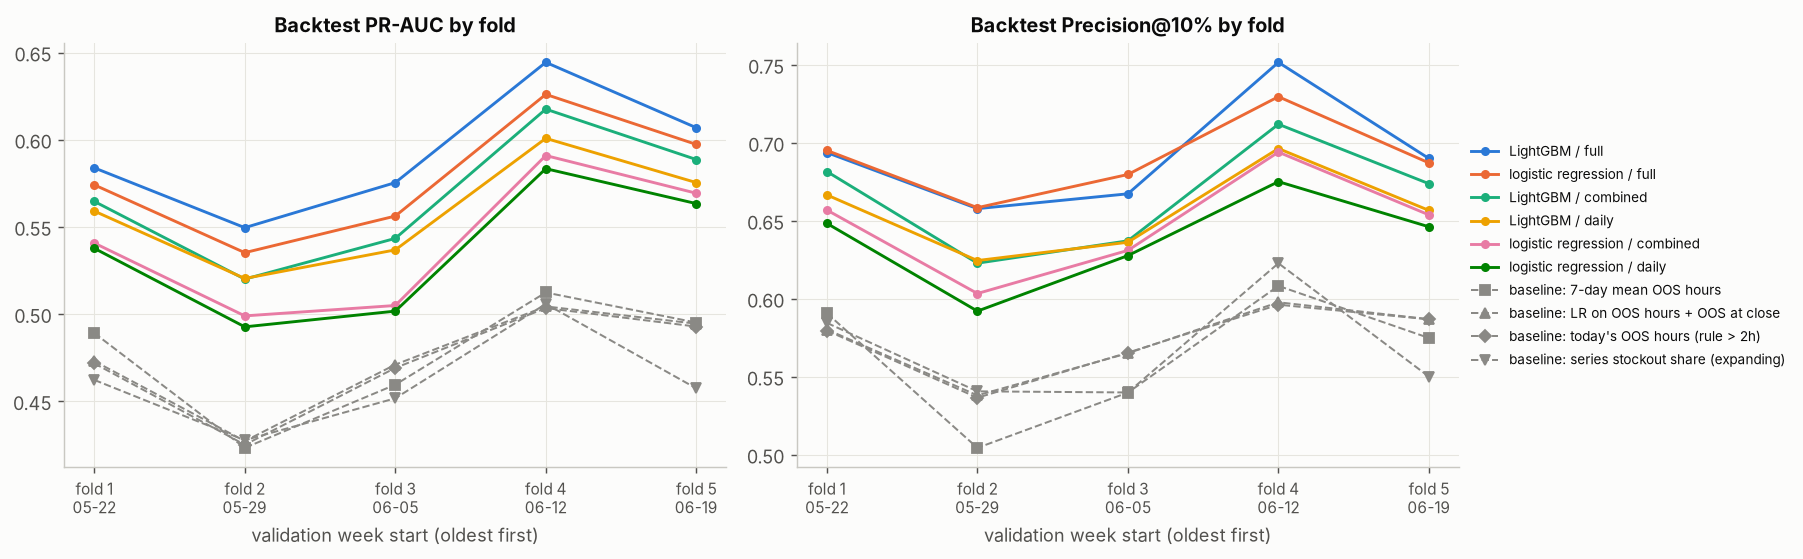

In [17]:
from IPython.display import Image
Image(filename=str(ROOT / "reports" / "figures" / "backtest_01_folds.png"))

## 7. Test results with confidence intervals

The test week (7 label days x 50,000 series) is scored once. Intervals come from a cluster bootstrap
over stores (1,000 resamples of the 898 stores, every model on the same draws), so they reflect
store-to-store variation, not only row noise. Precision@k is the share of real stockouts among the
top k% of series by score on each day, averaged over the 7 days: it is what a team with a fixed
daily review capacity would see. **Precision@10% (5,000 alerts per day) is the headline metric.**

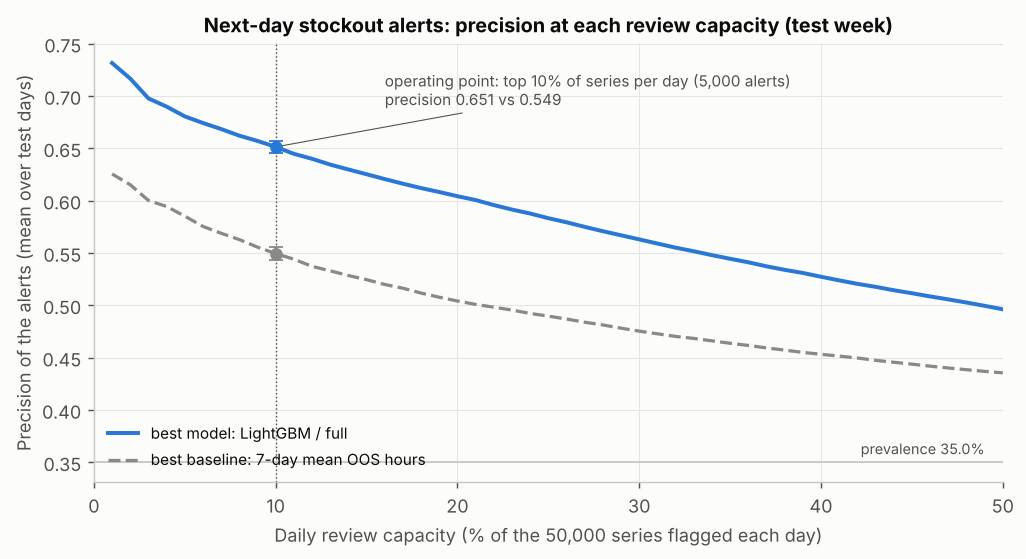

In [18]:
Image(filename=str(ROOT / "reports" / "figures" / "hero_precision_at_k.png"))

In [19]:
head = pd.read_csv(TABLES / "headline_test.csv")
ci = pd.read_csv(TABLES / "test_metrics_ci.csv")
display(head[["role", "label", "precision_at_10", "precision_at_10_lo", "precision_at_10_hi",
              "pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc"]].round(3))
ci[["label", "precision_at_10", "precision_at_10_lo", "precision_at_10_hi", "pr_auc", "pr_auc_lo",
    "pr_auc_hi", "roc_auc", "roc_auc_lo", "roc_auc_hi"]].round(3)

,role,label,precision_at_10,precision_at_10_lo,precision_at_10_hi,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
0,best baseline,baseline: 7-day mean OOS hours,0.549,0.543,0.555,0.466,0.462,0.471,0.636
1,rule baseline,baseline: today's OOS hours (rule > 2h),0.576,0.570,0.581,0.470,0.467,0.474,0.649
2,daily,LightGBM / daily,0.607,0.603,0.612,0.532,0.528,0.536,0.699
3,combined,LightGBM / combined,0.615,0.610,0.620,0.538,0.535,0.542,0.708
4,best model,LightGBM / full,0.651,0.646,0.656,0.567,0.563,0.571,0.729


,label,precision_at_10,precision_at_10_lo,precision_at_10_hi,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,roc_auc_lo,roc_auc_hi
0,baseline: today's OOS hours (rule > 2h),0.576,0.570,0.581,0.470,0.467,0.474,0.649,0.647,0.651
1,baseline: 7-day mean OOS hours,0.549,0.543,0.555,0.466,0.462,0.471,0.636,0.633,0.638
2,baseline: series stockout share (expanding),0.491,0.484,0.498,0.417,0.413,0.421,0.575,0.572,0.577
3,baseline: LR on OOS hours + OOS at close,0.577,0.572,0.582,0.472,0.468,0.476,0.650,0.648,0.652
4,logistic regression / daily,0.594,0.589,0.599,0.520,0.516,0.524,0.687,0.685,0.690
5,LightGBM / daily,0.607,0.603,0.612,0.532,0.528,0.536,0.699,0.696,0.701
6,logistic regression / weekly,0.519,0.512,0.526,0.462,0.458,0.467,0.630,0.627,0.633
7,LightGBM / weekly,0.516,0.509,0.523,0.460,0.455,0.464,0.632,0.629,0.635
8,logistic regression / category,0.518,0.511,0.523,0.469,0.464,0.473,0.650,0.647,0.653
9,LightGBM / category,0.527,0.522,0.534,0.478,0.474,0.482,0.657,0.654,0.660


In [20]:
diffs = pd.read_csv(TABLES / "test_paired_differences.csv")
diffs[diffs.metric.isin(["pr_auc", "precision_at_10", "roc_auc"])].round(4)

,comparison,model_a,model_b,metric,difference,ci_lo,ci_hi,share_draws_a_better,significant_95
0,best (lightgbm_full) vs best baseline (baselin...,lightgbm_full,baseline_mean7,pr_auc,0.1008,0.0979,0.1035,1.0,True
1,best (lightgbm_full) vs best baseline (baselin...,lightgbm_full,baseline_mean7,roc_auc,0.0931,0.0907,0.0955,1.0,True
4,best (lightgbm_full) vs best baseline (baselin...,lightgbm_full,baseline_mean7,precision_at_10,0.1020,0.0960,0.1081,1.0,True
8,best (lightgbm_full) vs rule baseline (baselin...,lightgbm_full,baseline_today,pr_auc,0.0965,0.0943,0.0990,1.0,True
9,best (lightgbm_full) vs rule baseline (baselin...,lightgbm_full,baseline_today,roc_auc,0.0799,0.0784,0.0814,1.0,True
12,best (lightgbm_full) vs rule baseline (baselin...,lightgbm_full,baseline_today,precision_at_10,0.0757,0.0703,0.0817,1.0,True
16,full vs combined (LightGBM),lightgbm_full,lightgbm_combined,pr_auc,0.0284,0.0265,0.0303,1.0,True
17,full vs combined (LightGBM),lightgbm_full,lightgbm_combined,roc_auc,0.0213,0.0200,0.0226,1.0,True
20,full vs combined (LightGBM),lightgbm_full,lightgbm_combined,precision_at_10,0.0368,0.0322,0.0409,1.0,True
24,combined vs daily (LightGBM),lightgbm_combined,lightgbm_daily,pr_auc,0.0067,0.0057,0.0077,1.0,True


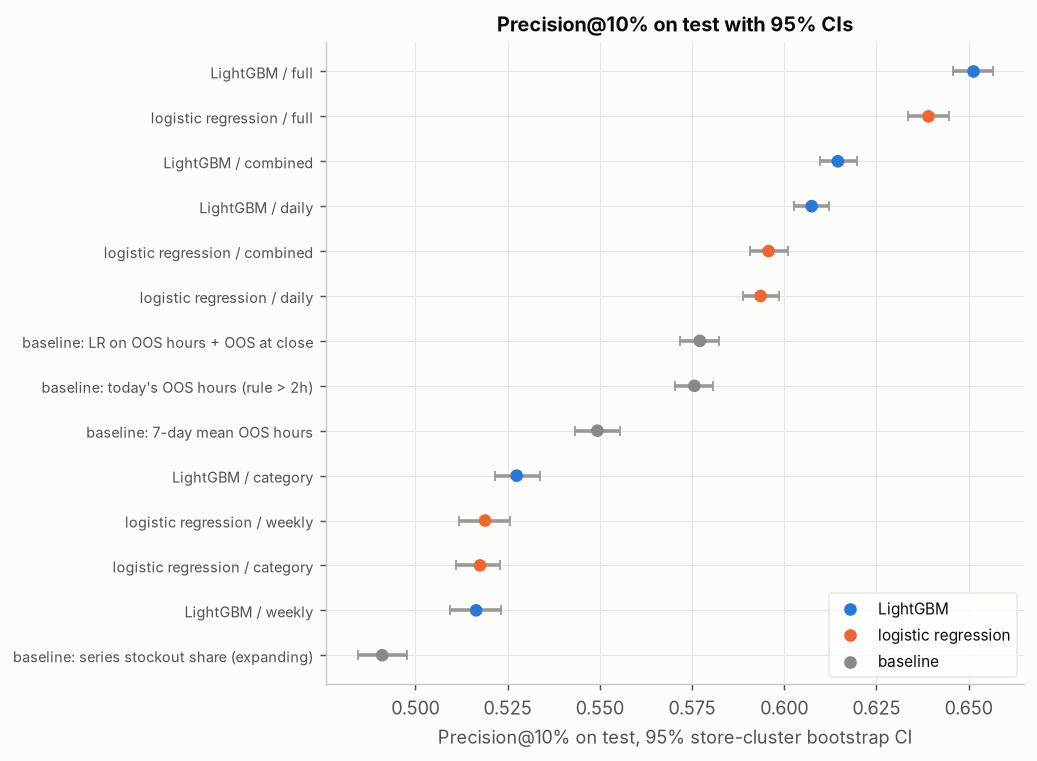

In [21]:
Image(filename=str(ROOT / "reports" / "figures" / "ci_01_precision_at_10.png"))

### Aggregation study and ablation

Which aggregation level carries the signal is answered with the four configs daily, weekly,
category and combined. The ablation removes one added group at a time from `full`.

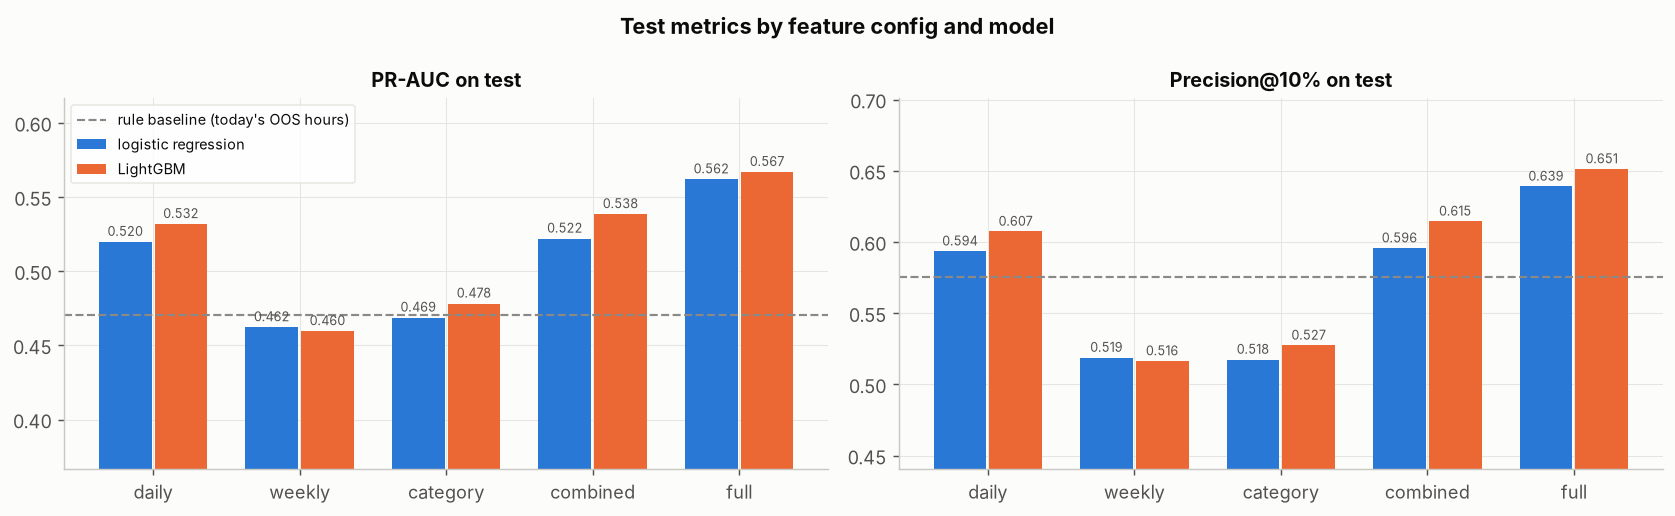

,entry,pr_auc_test,pr_auc_valid,precision_at_10_test,precision_at_10_valid,pr_auc_test_change_vs_full,pr_auc_valid_change_vs_full,precision_at_10_test_change_vs_full,precision_at_10_valid_change_vs_full,test_pr_auc_lo,test_pr_auc_hi
0,lightgbm_full,0.5669,0.6270,0.6513,0.7204,0.0000,0.0000,0.0000,0.0000,0.5630,0.5706
1,lightgbm_full_minus_intraday,0.5578,0.6229,0.6408,0.7184,-0.0091,-0.0041,-0.0105,-0.0020,0.5541,0.5617
2,lightgbm_full_minus_history,0.5638,0.6262,0.6459,0.7219,-0.0031,-0.0008,-0.0055,0.0014,0.5600,0.5675
3,lightgbm_full_minus_entity,0.5531,0.6092,0.6305,0.7052,-0.0139,-0.0178,-0.0209,-0.0153,0.5493,0.5568
4,lightgbm_full_minus_demand,0.5665,0.6259,0.6502,0.7199,-0.0005,-0.0011,-0.0011,-0.0005,0.5627,0.5703
5,lightgbm_combined,0.5385,0.6016,0.6145,0.6950,-0.0284,-0.0254,-0.0368,-0.0254,0.5346,0.5423


In [22]:
order = ["daily", "weekly", "category", "combined", "full"]
test = results[results.split == "test"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["pr_auc", "precision_at_10"]):
    x = np.arange(len(order))
    for j, (kind, color) in enumerate([("logreg", SERIES[0]), ("lightgbm", SERIES[1])]):
        vals = [test[test.entry == f"{kind}_{c}"][metric].iloc[0] for c in order]
        ax.bar(x + (j - 0.5) * 0.38, vals, width=0.36, color=color, label=modeling.MODEL_NAMES[kind])
        for xi, v in zip(x, vals):
            ax.text(xi + (j - 0.5) * 0.38, v + 0.004, f"{v:.3f}", ha="center", fontsize=7, color=TEXT_2)
    b = test[test.entry == "baseline_today"][metric].iloc[0]
    ax.axhline(b, color=NEUTRAL, ls="--", lw=1.2, label="rule baseline (today's OOS hours)")
    ax.set_xticks(x, order)
    ax.set_ylim(test[metric].min() - 0.05, test[metric].max() + 0.05)
    ax.set_title({"pr_auc": "PR-AUC", "precision_at_10": "Precision@10%"}[metric] + " on test")
axes[0].legend(fontsize=8, loc="upper left", frameon=True, facecolor="white", edgecolor="#e6e5df")
fig.suptitle("Test metrics by feature config and model", fontweight="bold")
save(fig, "model_01_metrics_by_config")
plt.show()
display(pd.read_csv(TABLES / "ablation_full.csv").round(4))

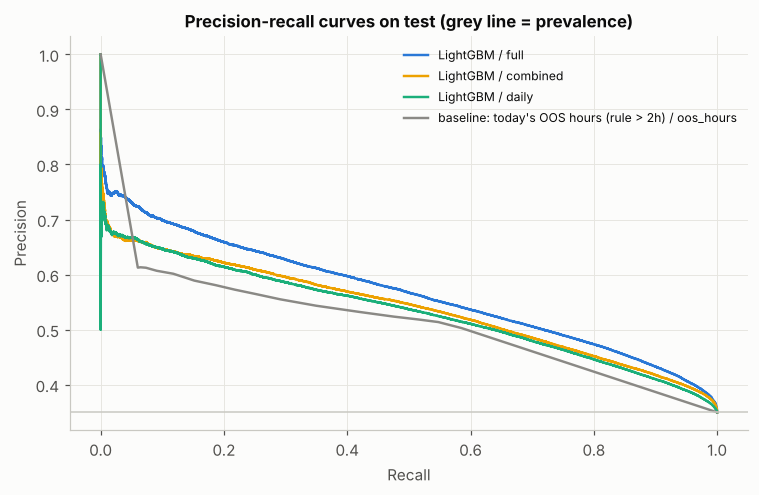

In [23]:
fig, ax = plt.subplots(figsize=(7, 4.6))
y = preds.label.values
for e, color in [(best, SERIES[0]), ("lightgbm_combined", SERIES[3]), ("lightgbm_daily", SERIES[2]),
                 ("baseline_today", NEUTRAL)]:
    p, r, _ = precision_recall_curve(y, preds[f"score_{e}"])
    ax.plot(r, p, color=color, lw=1.6, label=" / ".join(modeling.describe_entry(e)))
ax.axhline(y.mean(), color="#c9c8c2", lw=1)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves on test (grey line = prevalence)")
ax.legend(fontsize=8)
save(fig, "model_02_pr_curves")
plt.show()

## 8. Calibration

Platt and isotonic maps are fitted on the validation scores of the selected model and applied to
test. The map used for reporting is chosen by grouped (store) cross-validation on validation only.

,calibration,fitted_on,brier_test,ece_10_bins_test,mean_predicted_test,observed_rate_test,pr_auc_test,selected
0,raw,NaN,0.1963,0.0370,0.3128,0.3498,0.5669,False
1,platt,validation,0.1951,0.0209,0.3353,0.3498,0.5669,True
2,isotonic,validation,0.1950,0.0198,0.3354,0.3498,0.5647,False


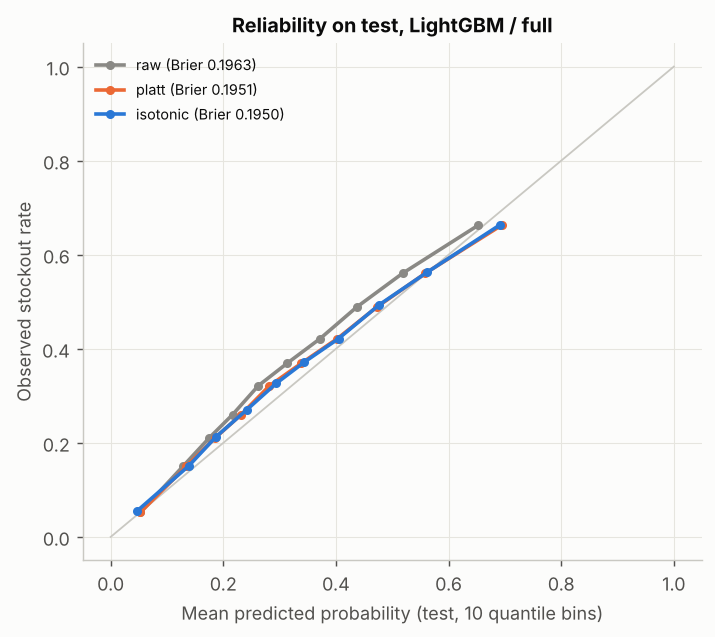

In [24]:
display(pd.read_csv(TABLES / "calibration_test.csv").round(4))
Image(filename=str(ROOT / "reports" / "figures" / "calibration_01_reliability.png"))

## 9. Where the model fails: slices

Test PR-AUC and precision@10% (computed within each slice) by first category, store volume decile
(mean daily sales over the train period), series stockout-history decile (share of train days with
more than 2 OOS hours) and day.

In [25]:
sl = pd.read_csv(TABLES / "slices_test.csv")
for dim, d in sl.groupby("slice", sort=False):
    print(dim); display(d.drop(columns="slice").round(3))

first_category_id


,value,n,prevalence,pr_auc_model,precision_at_10_model,pr_auc_baseline,precision_at_10_baseline,pr_auc_lift,pr_auc_over_prevalence
0,0,2555,0.342,0.405,0.464,0.360,0.349,0.045,0.063
1,1,42,0.000,NaN,0.000,NaN,0.000,NaN,NaN
2,2,28,0.214,0.792,NaN,0.445,NaN,0.347,0.578
3,3,574,0.237,0.599,0.679,0.432,0.571,0.167,0.362
4,4,76216,0.432,0.636,0.700,0.532,0.605,0.103,0.203
5,5,11550,0.196,0.514,0.609,0.352,0.457,0.161,0.317
6,6,420,0.090,0.222,0.310,0.101,0.095,0.121,0.132
7,7,7126,0.393,0.538,0.608,0.400,0.378,0.138,0.144
8,8,20195,0.356,0.586,0.669,0.465,0.544,0.121,0.231
9,9,14,0.286,0.729,NaN,0.321,NaN,0.408,0.443


store_volume_decile


,value,n,prevalence,pr_auc_model,precision_at_10_model,pr_auc_baseline,precision_at_10_baseline,pr_auc_lift,pr_auc_over_prevalence
32,1,13972,0.347,0.568,0.662,0.491,0.574,0.077,0.221
33,2,22666,0.341,0.564,0.648,0.473,0.562,0.091,0.223
34,3,31871,0.334,0.556,0.641,0.462,0.561,0.094,0.223
35,4,37555,0.343,0.569,0.652,0.463,0.552,0.106,0.226
36,5,40796,0.343,0.563,0.639,0.456,0.543,0.106,0.219
37,6,41608,0.342,0.562,0.641,0.463,0.550,0.099,0.220
38,7,49847,0.368,0.579,0.662,0.476,0.558,0.103,0.211
39,8,51009,0.358,0.574,0.657,0.469,0.549,0.104,0.216
40,9,41391,0.360,0.567,0.648,0.465,0.539,0.103,0.207
41,10,19285,0.345,0.558,0.631,0.458,0.511,0.100,0.214


series_history_decile


,value,n,prevalence,pr_auc_model,precision_at_10_model,pr_auc_baseline,precision_at_10_baseline,pr_auc_lift,pr_auc_over_prevalence
42,"(0.0434, 0.233]",37163,0.269,0.548,0.614,0.452,0.539,0.096,0.279
43,"(0.233, 0.278]",40558,0.310,0.524,0.608,0.408,0.472,0.117,0.214
44,"(0.278, 0.311]",40572,0.323,0.521,0.614,0.412,0.476,0.109,0.198
45,"(0.311, 0.333]",28686,0.326,0.513,0.612,0.402,0.462,0.111,0.187
46,"(0.333, 0.356]",29253,0.331,0.516,0.604,0.412,0.487,0.104,0.185
47,"(0.356, 0.389]",38976,0.335,0.523,0.615,0.416,0.492,0.107,0.188
48,"(0.389, 0.422]",32347,0.353,0.548,0.638,0.428,0.498,0.120,0.195
49,"(0.422, 0.478]",37814,0.368,0.560,0.647,0.450,0.521,0.110,0.192
50,"(0.478, 0.567]",32256,0.420,0.616,0.707,0.516,0.594,0.099,0.195
51,"(0.567, 0.989]",32375,0.487,0.670,0.734,0.618,0.677,0.052,0.183


day


,value,n,prevalence,pr_auc_model,precision_at_10_model,pr_auc_baseline,precision_at_10_baseline,pr_auc_lift,pr_auc_over_prevalence
52,2024-06-25,50000,0.341,0.556,0.657,0.469,0.542,0.087,0.215
53,2024-06-26,50000,0.311,0.536,0.630,0.454,0.556,0.082,0.226
54,2024-06-27,50000,0.262,0.455,0.541,0.377,0.454,0.078,0.193
55,2024-06-28,50000,0.293,0.492,0.576,0.410,0.500,0.082,0.199
56,2024-06-29,50000,0.444,0.654,0.763,0.549,0.623,0.105,0.210
57,2024-06-30,50000,0.391,0.611,0.700,0.509,0.587,0.102,0.220
58,2024-07-01,50000,0.407,0.607,0.692,0.514,0.583,0.094,0.200


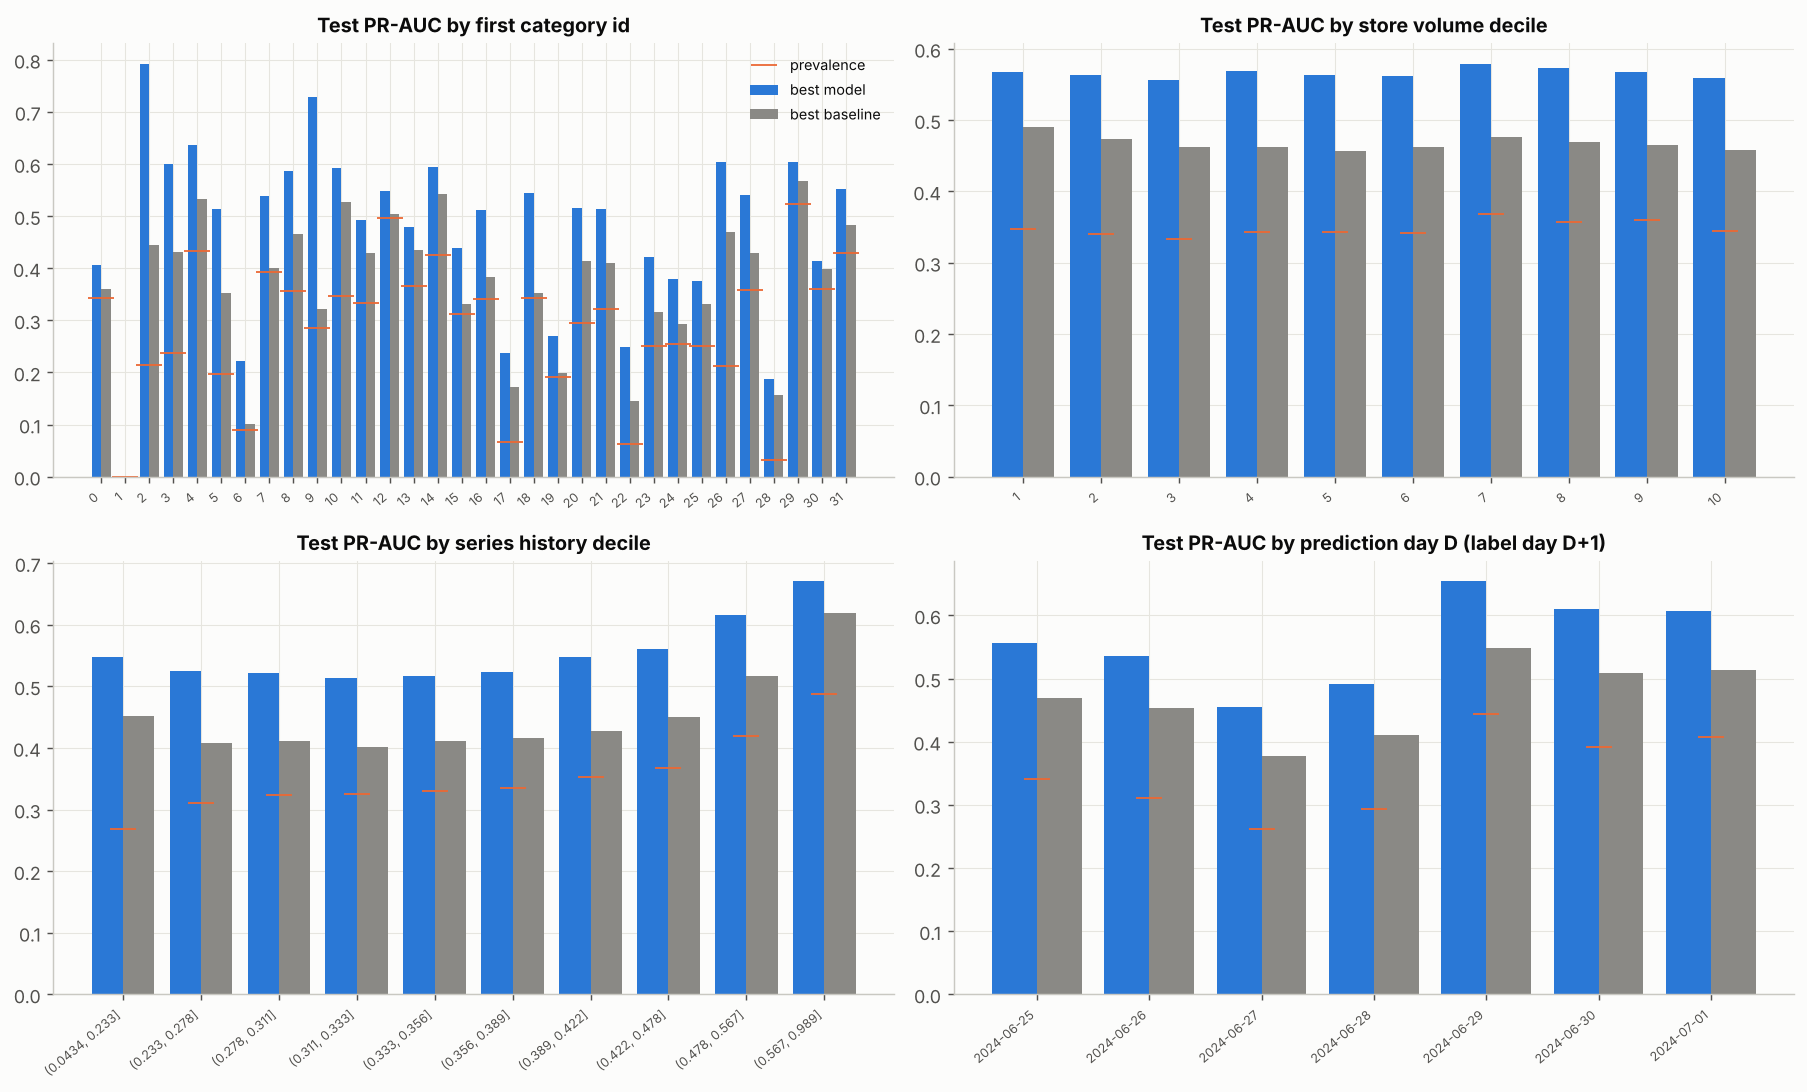

In [26]:
Image(filename=str(ROOT / "reports" / "figures" / "slices_01_pr_auc.png"))

## 10. What the model relies on: importance and SHAP

Permutation importance (validation sample) and Tree SHAP values (20,000 test rows) for the selected
model. Features are labeled by role: **actionable** (discount, promotion), **response
trigger** (recent and intraday stockouts, entity stockout rates, demand estimates) and
**descriptive** (weather, calendar, category ids). Importance describes what the model
uses to rank risk. **It is not causation.**

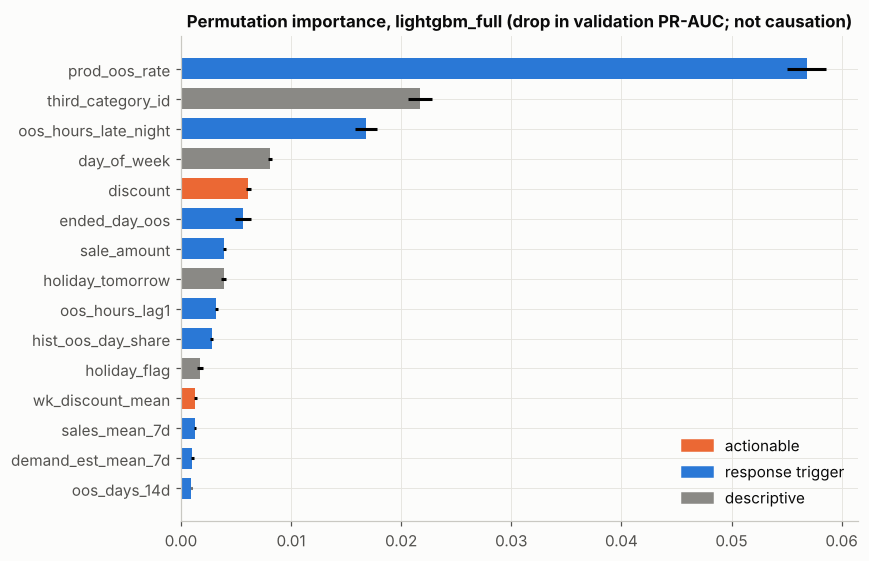

,feature,mean_abs_shap,role,group
0,prod_oos_rate,0.3724,response trigger,entity
1,oos_hours_late_night,0.2787,response trigger,intraday
2,ended_day_oos,0.1525,response trigger,intraday
3,third_category_id,0.1464,descriptive,entity
4,avg_temperature,0.1057,descriptive,daily
5,discount,0.0699,actionable,daily
6,day_of_week,0.0619,descriptive,calendar
7,sale_amount,0.0541,response trigger,daily
8,hist_oos_day_share,0.0419,response trigger,history
9,sales_mean_7d,0.0390,response trigger,daily


group
daily       0.6216
entity      0.6203
intraday    0.4723
calendar    0.1120
category    0.0874
weekly      0.0712
history     0.0657
demand      0.0594
Name: mean_abs_shap, dtype: float64

In [27]:
imp = pd.read_csv(TABLES / "feature_importance_best.csv")
shap_imp = pd.read_csv(TABLES / "shap_importance_test.csv")
top = imp.head(15).iloc[::-1]
role_color = {"actionable": SERIES[1], "response trigger": SERIES[0], "descriptive": NEUTRAL}
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top.feature, top.perm_importance_mean, xerr=top.perm_importance_std,
        color=[role_color[r] for r in top.role], height=0.7)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=r) for r, c in role_color.items()], loc="lower right")
ax.set_title(f"Permutation importance, {best} (drop in validation PR-AUC; not causation)")
save(fig, "importance_01_top_features")
plt.show()
display(shap_imp.head(20).round(4))
shap_imp.groupby(["group"]).mean_abs_shap.sum().sort_values(ascending=False).round(4)

In [28]:
role_summary = imp.groupby("role").agg(
    n_features=("feature", "size"),
    perm_importance_sum=("perm_importance_mean", "sum"),
    **({"gain_share_sum": ("gain_share", "sum")} if "gain_share" in imp else {}),
).sort_values("perm_importance_sum", ascending=False)
role_summary.to_csv(TABLES / "feature_importance_by_role.csv")
role_summary.round(4)

,n_features,perm_importance_sum,gain_share_sum
role,,,
response trigger,59,0.1015,0.7160
descriptive,11,0.0379,0.2653
actionable,7,0.0103,0.0187


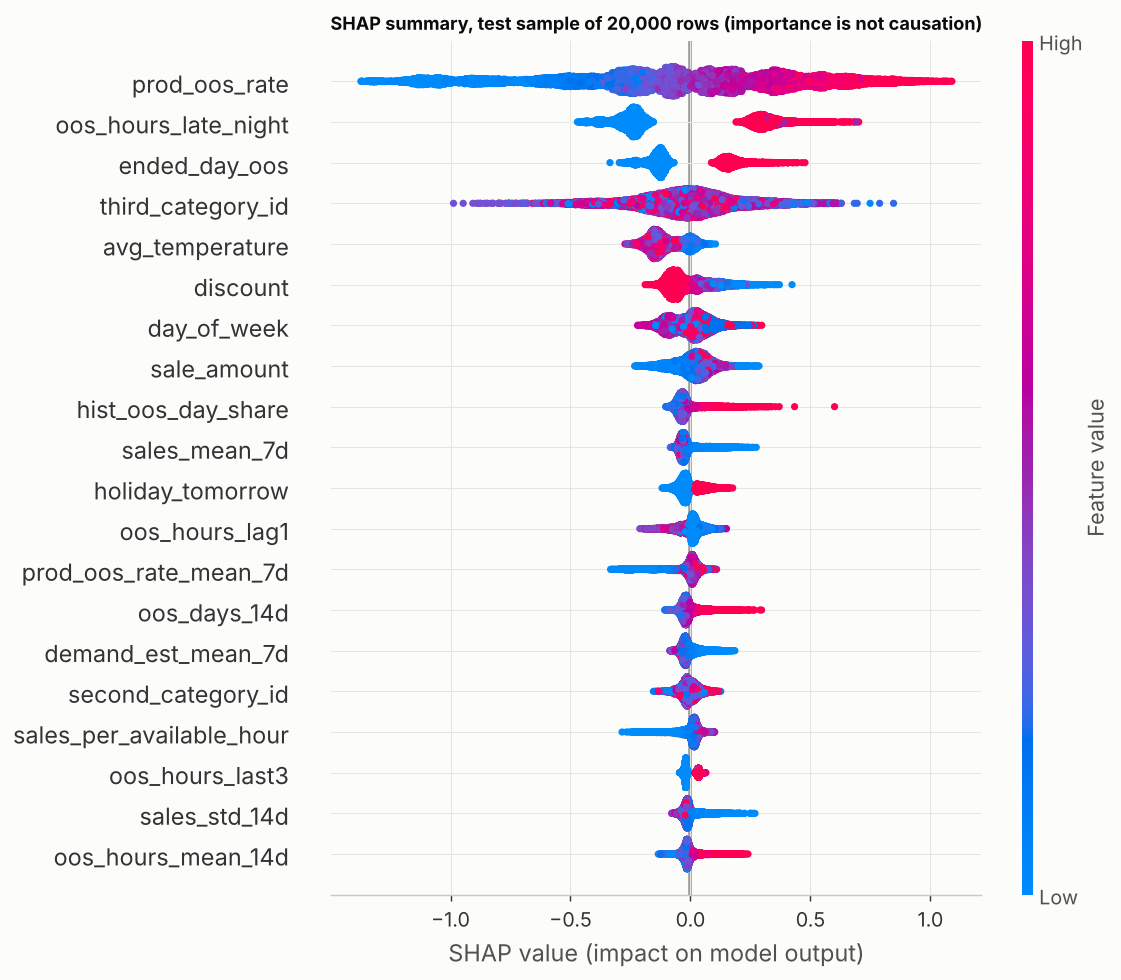

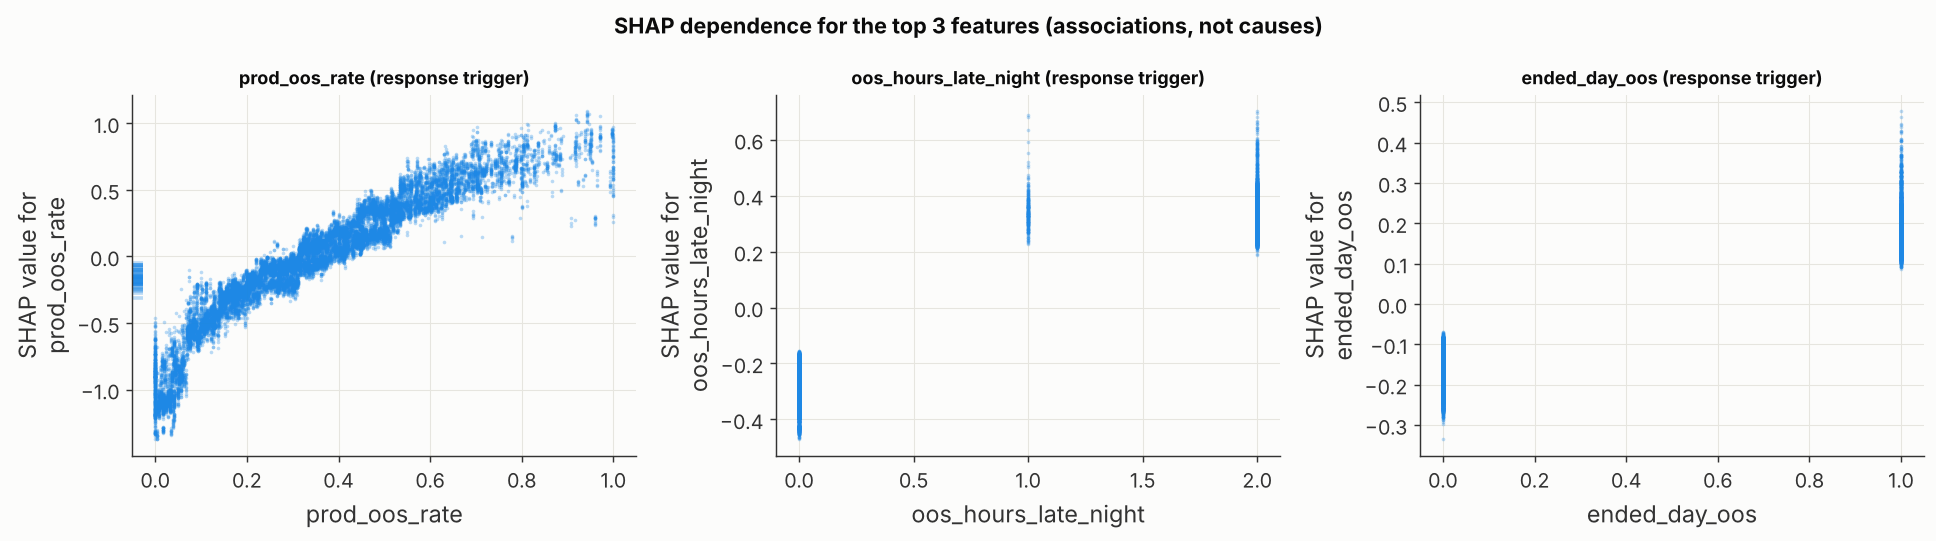

In [29]:
display(Image(filename=str(ROOT / "reports" / "figures" / "shap_01_summary.png")))
display(Image(filename=str(ROOT / "reports" / "figures" / "shap_02_dependence_top3.png")))

## 11. Results and suggested operating setup

### What the numbers say

Test set: 350,000 store-product-days (7 label days x 50,000 series), prevalence 35.0%. The PR-AUC
of a random ranking equals prevalence. Intervals are 95% store-cluster bootstrap CIs (1,000
resamples). Precision@10% is the share of real stockouts among the top 10% of series each day.
The model was selected by mean PR-AUC in a 5-fold rolling-origin backtest, not on test.

| Model | Precision@10% | PR-AUC | ROC-AUC | Backtest PR-AUC (mean ± sd) |
|---|---|---|---|---|
| Baseline: 7-day mean OOS hours (best baseline in the backtest) | 0.549 (0.543 to 0.555) | 0.466 (0.462 to 0.471) | 0.636 | 0.476 ± 0.035 |
| Baseline: today's OOS hours (rule > 2h) | 0.576 (0.570 to 0.581) | 0.470 (0.467 to 0.474) | 0.649 | 0.473 ± 0.030 |
| LightGBM, daily | 0.607 (0.603 to 0.612) | 0.532 (0.528 to 0.536) | 0.699 | 0.559 ± 0.032 |
| LightGBM, combined | 0.615 (0.610 to 0.620) | 0.538 (0.535 to 0.542) | 0.708 | 0.567 ± 0.038 |
| Logistic regression, full | 0.639 | 0.562 | 0.727 | 0.578 ± 0.035 |
| **LightGBM, full** | **0.651 (0.646 to 0.656)** | **0.567 (0.563 to 0.571)** | **0.729** | **0.592 ± 0.036** |

1. **Daily aggregation carries the signal.** With LightGBM, daily features reach a test PR-AUC
   of 0.532, category features 0.478 and last-completed-week features 0.460, below the one-line
   rule baseline (0.470). Combining the three levels adds a small gain over daily (+0.007
   PR-AUC, CI 0.006 to 0.008).
2. **The added features matter more than the aggregation level.** The `full` config (combined
   plus intraday, history, entity and demand features) adds +0.037 precision@10%
   (CI 0.032 to 0.041) and +0.028 PR-AUC over combined on test, and beats combined in all 5
   backtest folds. The entity group contributes the most: how often the same product is out of
   stock in the other stores today (leave-one-out, so the row's own store is excluded). The
   late-night out-of-stock hours of D come next. The censored-demand estimates add nothing
   measurable (less than 0.001 PR-AUC when removed).
3. **Model choice matters less than the information.** On `full`, logistic regression is close
   to LightGBM on backtest precision@10% (0.690 against 0.692) and trails it by 0.014 backtest
   PR-AUC and 0.012 test precision@10%.
4. **The baselines are strong and close to each other.** Stockouts persist, and every simple
   ranking (today's hours, 7-day mean, series history, a two-feature LR) lands at backtest PR-AUC
   0.46 to 0.48. On test the best model adds about 0.10 PR-AUC and 0.08 to 0.10 precision@10%
   over the two baselines in the table.
5. **Validation is more optimistic than test for every model, the baselines included.** Test
   precision@10% is 0.651 against 0.720 on validation, and the backtest folds range from 0.658
   to 0.752. Because the baselines drop too, this points to a harder late June and early July
   period rather than to overfitting, though one test week cannot settle it.
6. **What the best model relies on** (importance is not causation): the product's stockout rate
   in the other stores and the late-night out-of-stock hours (response triggers), the product
   category (descriptive) and discount (actionable, 6th by SHAP). Average temperature ranks 5th;
   it follows the season, so part of its weight may be a time trend rather than weather.

### Suggested operating setup

If this were run for a replenishment team: **LightGBM on the `full` feature set, used as a
ranked alert list with a fixed daily review capacity, starting at the top 10% of series (5,000
alerts per day).**

- **Lead time.** Every configuration produces its warning at the end of day D for day D+1, which
  leaves one overnight cycle to reorder, move stock or adjust a markdown. What differs is
  reaction speed. Weekly features change once a week and cannot react to a stockout that started
  today. The strongest signals (other stores running out today, the shelf being empty at 22:00)
  refresh daily, after closing.
- **False negatives versus false positives.** For perishables, a missed stockout costs a day of
  lost sales. A false alarm costs review time and, if acted on blindly, overstock that may spoil.
  At the F1-optimal threshold the model flags 49% of all store-products each day, which no team
  could review, so the cutoff is set by capacity rather than by F1. Each alert carries a
  calibrated probability (Platt, ECE 0.021 on test) and its top 3 contributors.
- **Complexity.** `full` needs four more SQL feature models than `combined`, each an aggregate
  over tables the pipeline already builds. Logistic regression on `full` is within 0.012
  precision@10% and simpler to explain, so it is a reasonable alternative. Daily-only LightGBM is
  a weaker one (-0.044 precision@10%).
- **Caveats.** The test window is one week. The store-cluster CIs cover variation across stores,
  not across weeks; the backtest spread (PR-AUC sd 0.036) is the better guide to week-to-week
  variation. The model is weak where stockouts are rare (for example first category 28,
  prevalence 3.1%, PR-AUC 0.187). Feature importance and SHAP values are associations: they say
  where the model looks, not what would happen if a discount or promotion were changed.

**Capacity trade-off on test.** At the top 10% of series per day, 65.1% of alerts are real
stockouts (54.9% for the best baseline, 57.6% for the rule "today > 2h"), and they catch 18.9%
of the next day's stockouts. The top 5% raises precision to 68.0% but catches only 9.9%. The top
20% gives precision 60.4% and recall 34.9%.